In [3]:
import numpy as np
from numpy import sqrt, pi, log, exp, linspace, diff, zeros
from numpy.linalg import eig, eigvals
import matplotlib.pyplot as plt

## This notebook aims to reproduce **Figure 1** of the following paper: [Brillouin-Wigner perturbation theory in open electromagnetic systems](https://iopscience.iop.org/article/10.1209/0295-5075/92/50010/pdf?casa_token=EI3v9y-qFNIAAAAA:tBj4r5au-336TDXGIbSpMH7XzEq2BcKeGIWVERgDlgFolgZuS3j3F7-WwU2ekV6E6NDKbXSjo5BFJGvmcHll5lOPHT0)

### The function below returns $V_{mn}$ defined by **Equation 16** of the paper. 

In [4]:
# slab_resonance gives the resonance positions for a slab terminated by a perfectly reflecting mirror 
def slab_resonance(m, n): # m indexes the mode number, n is the index of refraction
    return (pi/(2*n))*(m)-(1j/(2*n))*log((n+1)/(n-1)) # k_m*a
def mode_profile(m, n, k_m, z): # z is the normalized coordinate (in units of a)
    B_m = (-1j)**m/(2*n)
    return B_m*(exp(1j*n*k_m*z) + ((-1)**m)*exp(-1j*n*k_m*z))
def v_mn(delta_epsilon, z_v, mode_1, mode_2):
    delta_z = diff(z_v)[0]
    return (mode_1 * mode_2 * delta_epsilon * delta_z).sum()

In [88]:
m = 5
epsilon = 2.25
slab_resonance(m, sqrt(epsilon))

np.complex128(5.235987755982988-0.5364793041447j)

In [134]:
m_1 = 0; m_2 = -1;
n_z = 100000
z_v = linspace(-1, 1, n_z)

k_m_1 = slab_resonance(m_1, sqrt(epsilon))
mode_1 = mode_profile(m_1, sqrt(epsilon), k_m_1, z_v)

k_m_2 = slab_resonance(m_2, sqrt(epsilon))
mode_2 = mode_profile(m_2, sqrt(epsilon), k_m_2, z_v)

In [135]:
surface_term = (mode_1[0]*mode_2[0] + mode_1[-1]*mode_2[-1])/(1j*(k_m_1 + k_m_2))
integral_term = epsilon*(mode_1 * mode_2).sum()*diff(z_v)[0]

In [136]:
(integral_term -  surface_term).round(4)

np.complex128(0j)

In [39]:
delta_epsilon = 100
n_z = 100000
epsilon = 2.25
perturbation_z_v = linspace(1/2, 1, n_z)
max_m = 200
hamiltonian_matrix = zeros((2*max_m+1, 2*max_m+1), dtype=complex)

for (m_1_idx, m_1) in enumerate(range(-max_m, max_m+1)):
    if (m_1_idx % 20 == 0):
        print(f"m_1 = {m_1}")
    k_m_1 = slab_resonance(m_1, sqrt(epsilon))
    mode_1 = mode_profile(m_1, sqrt(epsilon), k_m_1, perturbation_z_v)
    hamiltonian_matrix[m_1_idx, m_1_idx] += 1/k_m_1

    for (m_2_idx, m_2) in enumerate(range(-max_m, max_m+1)):
        k_m_2 = slab_resonance(m_2, sqrt(epsilon))
        mode_2 = mode_profile(m_2, sqrt(epsilon), k_m_2, perturbation_z_v)
        off_diagonal_normalization = 2*sqrt(k_m_1*k_m_2)
        if off_diagonal_normalization.imag > 0: 
            off_diagonal_normalization = -off_diagonal_normalization
        hamiltonian_matrix[m_1_idx, m_2_idx] += v_mn(delta_epsilon, perturbation_z_v, mode_1, mode_2)/off_diagonal_normalization

m_1 = -200
m_1 = -180
m_1 = -160
m_1 = -140
m_1 = -120
m_1 = -100
m_1 = -80
m_1 = -60
m_1 = -40
m_1 = -20
m_1 = 0
m_1 = 20
m_1 = 40
m_1 = 60
m_1 = 80
m_1 = 100
m_1 = 120
m_1 = 140
m_1 = 160
m_1 = 180
m_1 = 200


In [40]:
#qnm_inv_frequencies, qnm_profiles = eig(hamiltonian_matrix)
qnm_inv_frequencies = eigvals(hamiltonian_matrix)
qnm_frequencies = 1/qnm_inv_frequencies
qnm_frequencies_real = qnm_frequencies.real
qnm_frequencies_imag = qnm_frequencies.imag

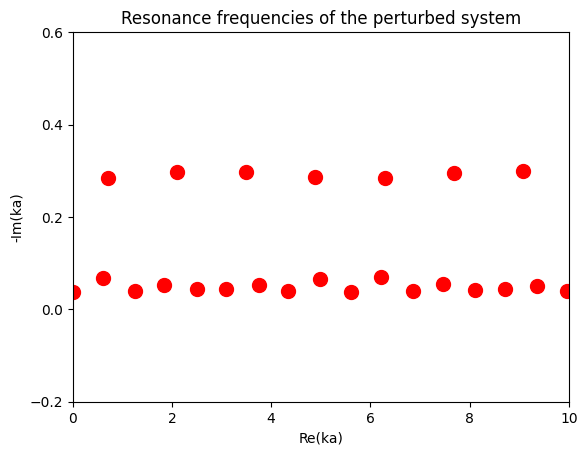

In [49]:
s=100
plt.scatter(qnm_frequencies_real, -qnm_frequencies_imag, s=s, color="red")
plt.xlim(0, 10)
#plt.ylim(0, 1)
plt.ylim(-0.2, 0.6);
plt.yticks([-0.2, 0, 0.2, 0.4, 0.6]);
plt.title("Resonance frequencies of the perturbed system");
plt.xlabel("Re(ka)")
plt.ylabel("-Im(ka)");